# 🚗 Road Traffic Accident Analysis
---
## 1. Project Overview

Hello everyone. Today I will share what I learned from road accident data. It covers 12,316 accidents: who was driving, the road and weather, what went wrong, and how badly people were hurt. My goal is simple: find clear patterns that can help make roads safer.

> 📝 **Questions this project answers:** accident timing and day/night, driver experience, accident severity, accident location, collision type, accident causes.

---
## 2. Understanding the Data

Let's start by getting to know the data. Each row is one accident. There are 32 columns about the driver, the vehicle, the road, the weather, the people hurt, and how serious the accident was.

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Look for the file in the current folder
PATH = next(p for p in ["RTA Dataset -  LMS.csv", "RTA Dataset - LMS.csv"] if os.path.exists(p))
df = pd.read_csv(PATH)

print("Dataset shape:", df.shape)

Dataset shape: (12316, 32)


In [4]:
display(df.head())
print("\nColumns:", len(df.columns))
print("Rows:", len(df))

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury



Columns: 32
Rows: 12316


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

---
## 3. Data Cleaning

Next, cleaning. I checked for repeated rows and found none. Some columns have blank spots. I did not guess them; each chart only uses rows that are filled in. I also removed extra spaces from the text, so one place name is not counted as two.

> 📝 **Cleaning steps:** (1) check blank values, (2) check repeated rows, (3) remove extra spaces from text columns. Blank values are left as they are, not guessed. One place label, `Rural village areasOffice areas` (about 20 rows), looks like two names stuck together. I left it, because I can't tell which place was meant.

In [7]:
# Confirm actual missing values after the cleaning process
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Remaining actual missing values:")
display(missing if not missing.empty else pd.Series(["None"], index=["Status"]))

Remaining actual missing values:


Defect_of_vehicle          4427
Service_year_of_vehicle    3928
Work_of_casuality          3198
Fitness_of_casuality       2635
Type_of_vehicle             950
Types_of_Junction           887
Driving_experience          829
Educational_level           741
Vehicle_driver_relation     579
Owner_of_vehicle            482
Lanes_or_Medians            385
Vehicle_movement            308
Area_accident_occured       239
Road_surface_type           172
Type_of_collision           155
Road_allignment             142
dtype: int64

In [8]:
# Confirm exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [9]:
# Remove extra spaces from every text column
# (so " Office areas" and "Office areas" count as the same place)
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip()

# Check: each place name should now appear only once
df["Area_accident_occured"].value_counts(dropna=False)

Area_accident_occured
Other                              3819
Office areas                       3451
Residential areas                  2060
Church areas                       1060
Industrial areas                    456
School areas                        415
Recreational areas                  328
NaN                                 239
Outside rural areas                 218
Hospital areas                      121
Market areas                         63
Rural village areas                  44
Unknown                              22
Rural village areasOffice areas      20
Name: count, dtype: int64

---
## 4. Feature Engineering

Then I added new columns: the hour of the accident, day or night, and whether the driver is experienced. Less than two years of driving, or no licence, counts as inexperienced.

> 📝 **New columns:** `Hour` (0–23), `Time_period` (Night / Morning / Afternoon / Evening), `Driver_experience_group` (Inexperienced: under 2 years or no licence; Experienced: 2 years or more), `Day_Night` (Day if light is "Daylight", otherwise Night).

In [13]:
# Convert time and create Hour
df["Time"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.time
df["Hour"] = pd.to_datetime(df["Time"].astype(str), format="%H:%M:%S").dt.hour

# Create time period
df["Time_period"] = pd.cut(
    df["Hour"],
    bins=[-1, 11, 16, 20, 23],
    labels=["Morning", "Afternoon", "Evening", "Night"],
    ordered=False
)

# Driver experience grouping
df["Driver_experience_group"] = df["Driving_experience"].map({
    "Below 1yr": "Inexperienced",
    "1-2yr": "Inexperienced",
    "2-5yr": "Experienced",
    "5-10yr": "Experienced",
    "Above 10yr": "Experienced",
    "No Licence": "Inexperienced"
})

# Day/Night based on recorded light condition
df["Day_Night"] = df["Light_conditions"].apply(
    lambda x: "Day" if x == "Daylight" else "Night"
)

display(df[[
    "Time", "Hour", "Time_period",
    "Driving_experience", "Driver_experience_group",
    "Light_conditions", "Day_Night"
]].head())

# Save the processed dataset
df.to_csv("RTA_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Final dataset shape:", df.shape)

,Time,Hour,Time_period,Driving_experience,Driver_experience_group,Light_conditions,Day_Night
0,17:02:00,17,Evening,1-2yr,Inexperienced,Daylight,Day
1,17:02:00,17,Evening,Above 10yr,Experienced,Daylight,Day
2,17:02:00,17,Evening,1-2yr,Inexperienced,Daylight,Day
3,01:06:00,1,Morning,5-10yr,Experienced,Darkness - lights lit,Night
4,01:06:00,1,Morning,2-5yr,Experienced,Darkness - lights lit,Night


Cleaned dataset saved successfully.
Final dataset shape: (12316, 36)


---
## 5. Exploratory Data Analysis (EDA)

Now I explore the data. I compare groups with percentages, so bigger groups do not look bad just for being bigger. 

### EDA 1 — Collision Type by Day/Night

One: do collisions look different by day and night? Not really.

> 📝 Exact numbers: vehicle-with-vehicle collisions are 72.6% by day and 71.1% at night. Rollovers are 3.1% by day and 3.7% at night.

In [14]:
collision_daynight = pd.crosstab(
    df["Day_Night"],
    df["Type_of_collision"],
    normalize="index"
).round(3) * 100

display(collision_daynight)

Type_of_collision,Collision with animals,Collision with pedestrians,Collision with roadside objects,Collision with roadside-parked vehicles,Fall from vehicles,Other,Rollover,Unknown,Vehicle with vehicle collision,With Train
Day_Night,,,,,,,,,,
Day,1.4,7.2,14.6,0.5,0.3,0.2,3.1,0.1,72.6,0.1
Night,1.5,7.9,15.0,0.3,0.2,0.1,3.7,0.1,71.1,0.1


### EDA 2 — Collision Type by Driver Experience

Two: do new and experienced drivers crash in different ways?

In [15]:
collision_experience = pd.crosstab(
    df["Type_of_collision"],
    df["Driver_experience_group"],
    normalize="columns"
).round(3) * 100

display(collision_experience)

Driver_experience_group,Experienced,Inexperienced
Type_of_collision,,
Collision with animals,1.3,1.5
Collision with pedestrians,7.2,7.6
Collision with roadside objects,15.4,13.8
Collision with roadside-parked vehicles,0.4,0.5
Fall from vehicles,0.3,0.4
Other,0.2,0.2
Rollover,3.0,4.2
Unknown,0.1,0.1
Vehicle with vehicle collision,72.1,71.7


### EDA 3 — Accident Severity by Driver Age

Three: which driver ages appear most in fatal, serious, and slight accidents?

In [16]:
severity_age = pd.crosstab(
    df["Accident_severity"],
    df["Age_band_of_driver"],
    normalize="index"
).round(3) * 100

display(severity_age)

Age_band_of_driver,18-30,31-50,Over 51,Under 18,Unknown
Accident_severity,,,,,
Fatal injury,39.2,34.2,15.2,7.6,3.8
Serious Injury,34.7,31.0,14.7,9.7,9.9
Slight Injury,34.6,33.5,12.5,6.2,13.2


### EDA 4 — Accident Cause by Place

Four: what causes accidents in different places?

In [17]:
cause_area = pd.crosstab(
    df["Cause_of_accident"],
    df["Area_accident_occured"],
    normalize="columns"
).round(3) * 100

display(cause_area)

Area_accident_occured,Church areas,Hospital areas,Industrial areas,Market areas,Office areas,Other,Outside rural areas,Recreational areas,Residential areas,Rural village areas,Rural village areasOffice areas,School areas,Unknown
Cause_of_accident,,,,,,,,,,,,,
Changing lane to the left,11.9,17.4,9.6,6.3,11.9,12.5,14.7,13.4,11.4,9.1,10.0,8.9,9.1
Changing lane to the right,14.5,14.0,15.4,9.5,15.4,14.0,13.3,10.4,15.0,9.1,30.0,17.8,18.2
Driving at high speed,1.2,0.8,1.8,1.6,1.3,1.4,0.9,1.2,1.7,2.3,0.0,1.0,0.0
Driving carelessly,11.1,9.9,11.0,11.1,10.8,11.9,14.2,9.5,11.6,20.5,0.0,11.3,22.7
Driving to the left,2.7,2.5,2.2,3.2,2.0,2.4,1.8,2.1,2.5,0.0,0.0,3.1,0.0
Driving under the influence of drugs,3.4,5.8,2.0,4.8,2.7,2.6,2.3,1.8,3.1,2.3,0.0,2.9,0.0
Drunk driving,0.3,0.0,0.0,0.0,0.2,0.2,0.5,0.6,0.3,0.0,0.0,0.0,0.0
Getting off the vehicle improperly,1.5,1.7,2.4,3.2,1.5,1.7,1.4,1.2,1.2,0.0,10.0,2.2,4.5
Improper parking,0.4,0.0,0.2,0.0,0.2,0.2,0.0,0.3,0.1,0.0,0.0,0.2,0.0


### EDA 5 — Road Surface by Day/Night

Five: are road conditions different between day and night accidents?


In [18]:
road_daynight = pd.crosstab(
    df["Day_Night"],
    df["Road_surface_conditions"],
    normalize="index"
).round(3) * 100

road_daynight

Road_surface_conditions,Dry,Flood over 3cm. deep,Snow,Wet or damp
Day_Night,,,,
Day,81.3,0.0,0.6,18.1
Night,62.1,0.0,0.6,37.3


---
## 6. Insights

### Insight 1 — Driver Experience and Collision Type

Insight one: driver experience. New and experienced drivers crash in very similar ways. For both, about 72 out of every 100 accidents are one vehicle hitting another. The only clear gap is rollovers: about 4 out of 100 for new drivers, and 3 for experienced ones.

> 📝 **Exact numbers:** vehicle-with-vehicle collisions: 72.1% (experienced) and 71.7% (inexperienced). Rollovers: 3.0% (experienced) and 4.2% (inexperienced). About 830 accidents with no experience record are left out.

### Insight 2 — Driver Age and Severity

Insight two: driver age. Drivers aged 18 to 30 are the biggest group at every injury level: about 39 out of 100 fatal accidents, and about 35 of serious and slight ones. This does not prove young drivers are riskier. There may just be more of them.

> 📝 **Exact numbers:** drivers aged 18–30 make up 39.2% of fatal, 34.7% of serious and 34.6% of slight accidents. Drivers aged 31–50 are second at every level. This shows *who is in the accidents*, not *who is most at risk*. Fatal accidents are only about 160 cases, so their percentages can swing a lot.

### Insight 3 — Accident Cause and Place

Insight three: causes. In most places, the top cause is no distancing, which means not keeping a safe gap. It is about 21 out of 100 accidents in recreational areas, and 19 in church and office areas. One warning: the biggest place group is called Other, so place records need to improve.

> 📝 **Exact numbers:** "No distancing" is 21.4% in recreational areas, 19.0% in church areas and 18.6% in office areas. It is the top cause everywhere except hospital areas, where changing lanes to the left comes first. "Changing lanes to the right" is 15.4% in industrial areas and 15.0% in residential areas. "Other" is the biggest place group (about 3,800 accidents). These are counts, not risk: busy places will have more accidents.

### Insight 4 — Day, Night and Wet Roads

Insight four: day and night. At night, about 37 out of 100 accidents happen on wet or damp roads. In the day, only 18. That does not prove wet roads cause more crashes, but it shows us where to look next.

> 📝 **Exact numbers (confirm with EDA 5):** wet or damp roads are 37.3% of night accidents and 18.1% of day accidents. Dry roads are 62.1% at night and 81.3% in the day. This shows a pattern, not a cause.

---
## 7. Charts

Now the charts that back this up.

### Chart 1 — Top Collision Types by Driver Experience

This chart shows the five most common collision types for each driver group. The two sides look almost the same.

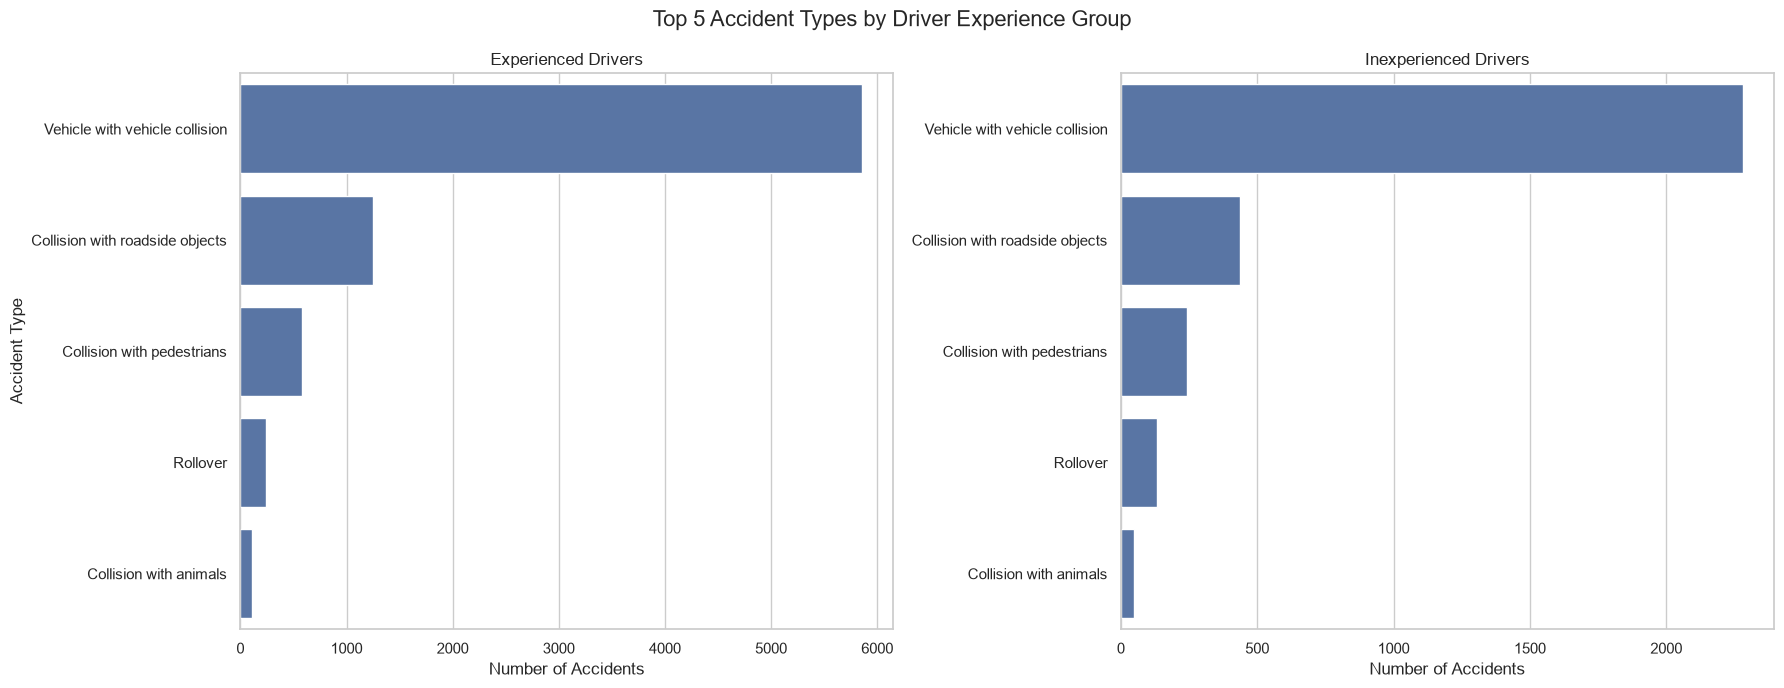

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("Top 5 Accident Types by Driver Experience Group", fontsize=16)

exp_data = (
    df[df["Driver_experience_group"] == "Experienced"]
    ["Type_of_collision"].value_counts().head(5)
)

inexp_data = (
    df[df["Driver_experience_group"] == "Inexperienced"]
    ["Type_of_collision"].value_counts().head(5)
)

sns.barplot(ax=axes[0], x=exp_data.values, y=exp_data.index)
axes[0].set_title("Experienced Drivers")
axes[0].set_xlabel("Number of Accidents")
axes[0].set_ylabel("Accident Type")

sns.barplot(ax=axes[1], x=inexp_data.values, y=inexp_data.index)
axes[1].set_title("Inexperienced Drivers")
axes[1].set_xlabel("Number of Accidents")
axes[1].set_ylabel("")
plt.savefig("charts/Accident_Types.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Chart 2 — Collision Types in Bad Weather

In bad weather, one vehicle hitting another is by far the most common.

> 📝 This chart groups all non-normal weather together.

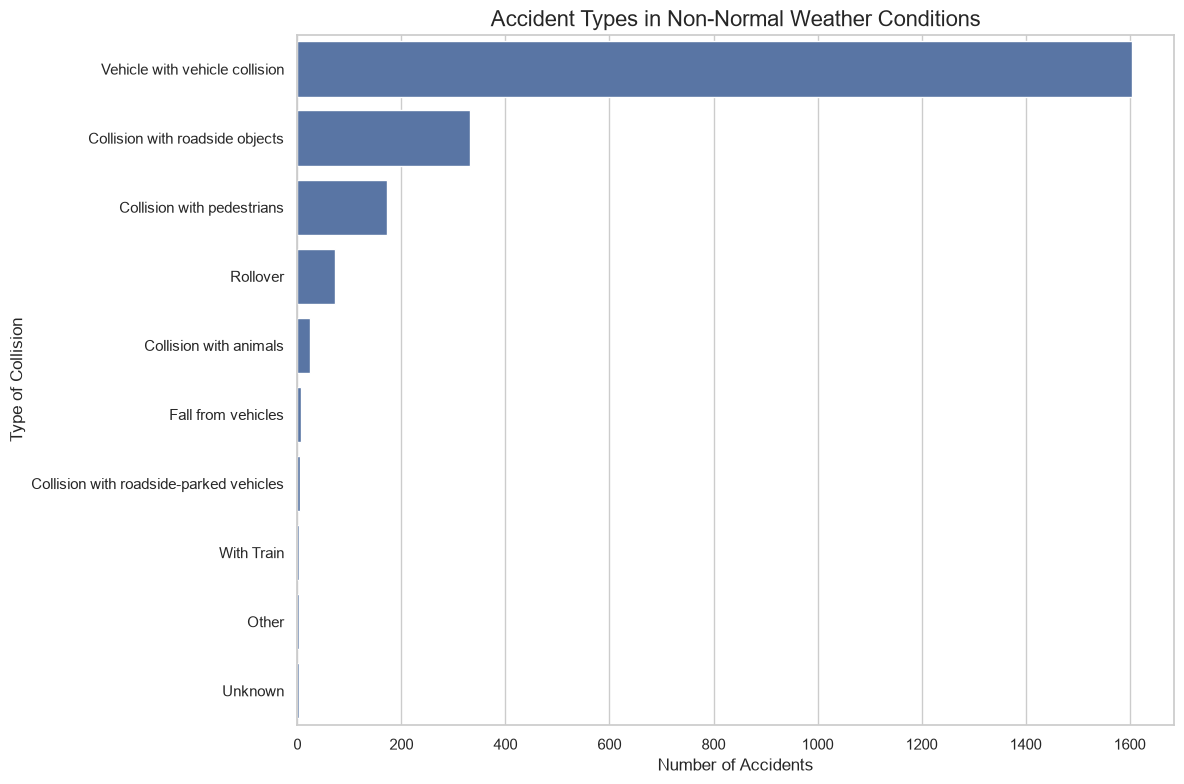

In [23]:
bad_weather_df = df[df["Weather_conditions"] != "Normal"]

plt.figure(figsize=(12, 8))
sns.countplot(
    y="Type_of_collision",
    data=bad_weather_df,
    order=bad_weather_df["Type_of_collision"].value_counts().index
)
plt.title("Accident Types in Non-Normal Weather Conditions", fontsize=16)
plt.xlabel("Number of Accidents")
plt.ylabel("Type of Collision")
plt.tight_layout()
plt.savefig("charts/Accident_Types_in_Non-Normal_Weather_Conditions.png", dpi=300, bbox_inches="tight")
plt.show()

### Chart 3 — How Serious Are the Accidents?

This pie chart shows how serious accidents are. About 85 out of 100 caused slight injuries, 14 caused serious injuries, and only about 1 was deadly. Deadly accidents are rare, so their numbers need extra care.

> 📝 **Exact numbers:** slight 84.6%, serious 14.2%, fatal 1.3% (about 160 accidents).

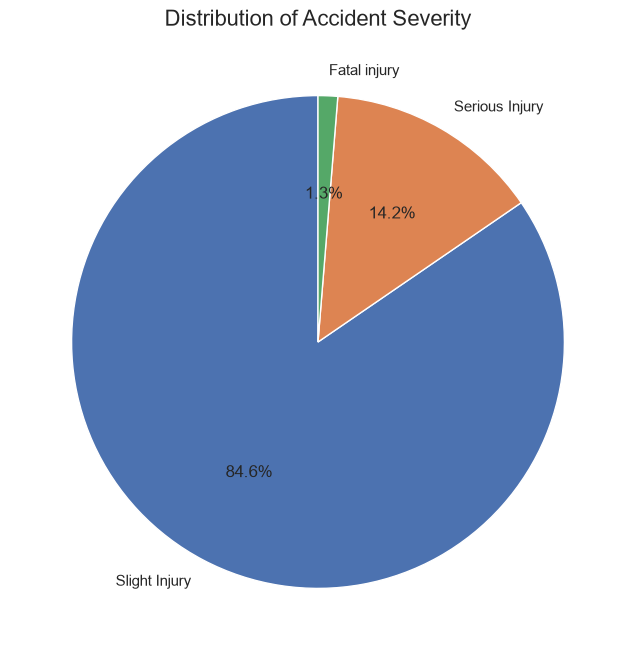

In [24]:
plt.figure(figsize=(8, 8))

severity_counts = df["Accident_severity"].value_counts()

plt.pie(
    severity_counts,
    labels=severity_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Accident Severity", fontsize=16)
plt.savefig("charts/Distribution_of_Accident_Severity.png", dpi=300, bbox_inches="tight")
plt.show()

### Chart 4 — Accidents by Place

And this chart shows accidents by place. Other, office, and residential areas have the most.


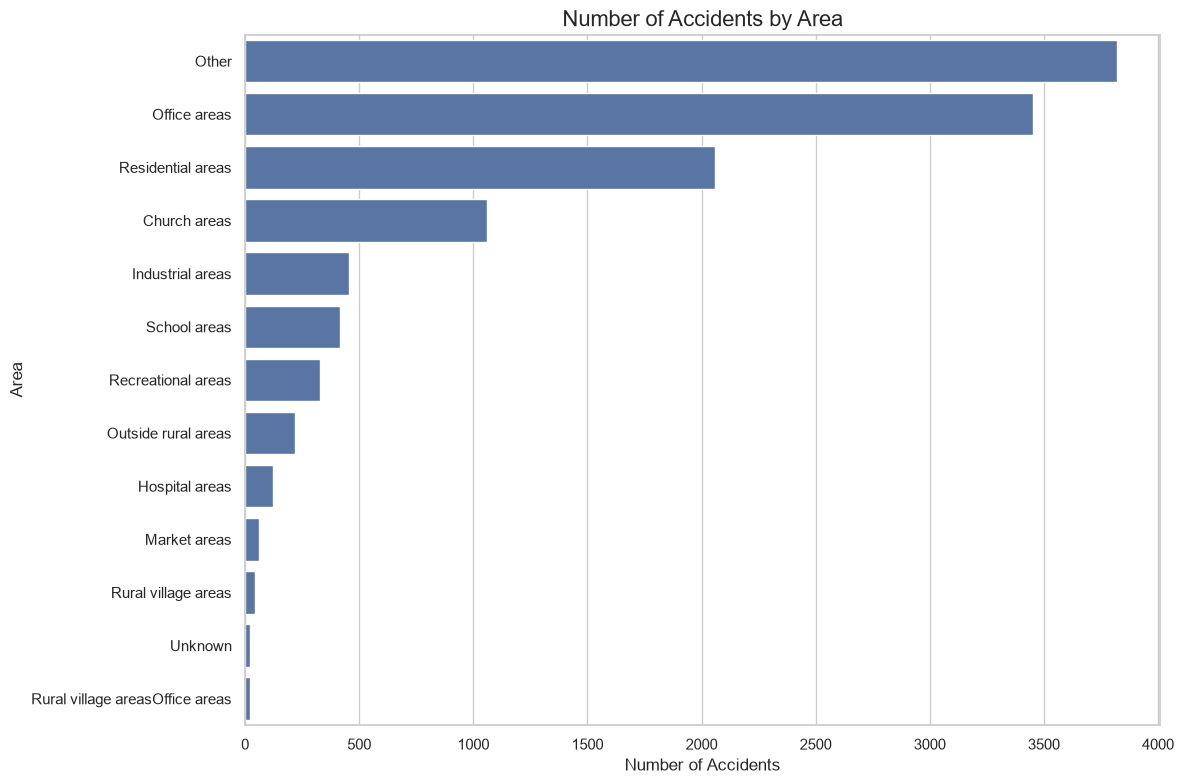

In [25]:
plt.figure(figsize=(12, 8))

sns.countplot(
    y="Area_accident_occured",
    data=df,
    order=df["Area_accident_occured"].value_counts().index
)

plt.title("Number of Accidents by Area", fontsize=16)
plt.xlabel("Number of Accidents")
plt.ylabel("Area")
plt.tight_layout()
plt.savefig("charts/Number_of_Accidents_by_Area.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 8. Conclusion

To finish: new and experienced drivers crash in similar ways, young drivers appear most, and not keeping a safe distance is a repeated problem. Wet roads matter more at night. My advice: run safe-distance campaigns, improve lights and drainage, and collect cleaner place data. Thank you for watching.

> 📝 **Limits:** these results show patterns, not causes. They also do not account for how many people drive in each group or place.